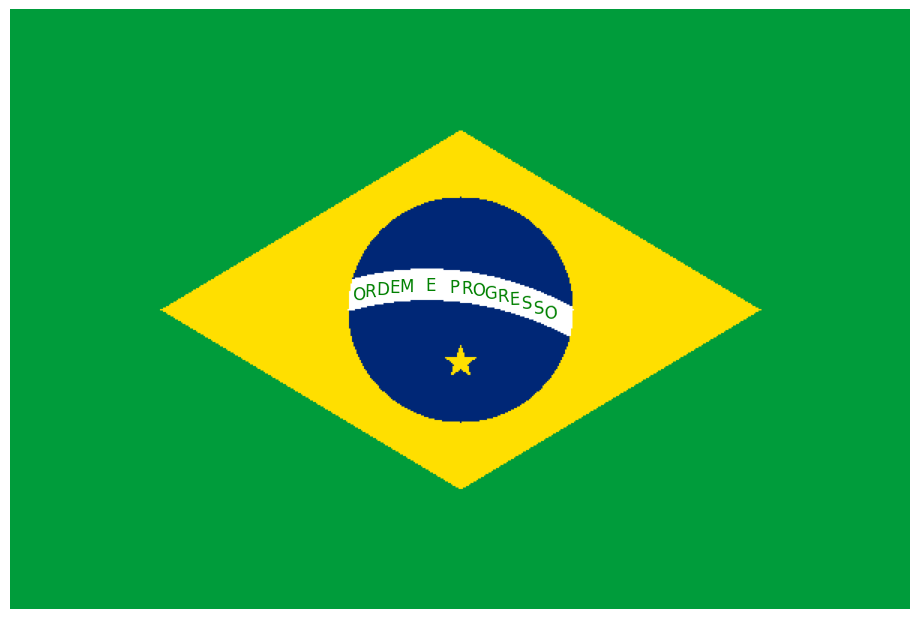

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path

height, width = 400, 600
img = np.ones((height, width, 3), dtype=np.uint8) * 255

GREEN = np.array([0, 156, 59], dtype=np.uint8)
YELLOW = np.array([255, 223, 0], dtype=np.uint8)
BLUE = np.array([0, 39, 118], dtype=np.uint8)
WHITE = np.array([255, 255, 255], dtype=np.uint8)

img[:] = GREEN

# ---------------- Diamond ----------------
diamond = np.array([
    [300, 80],
    [500, 200],
    [300, 320],
    [100, 200]
])

def point_in_polygon(x, y, poly):
    inside = False
    j = len(poly) - 1
    for i in range(len(poly)):
        xi, yi = poly[i]
        xj, yj = poly[j]

        if ((yi > y) != (yj > y)) and \
           (x < (xj - xi) * (y - yi) / (yj - yi + 1e-9) + xi):
            inside = not inside

        j = i
    return inside

for y in range(height):
    for x in range(width):
        if point_in_polygon(x, y, diamond):
            img[y, x] = YELLOW


# ---------------- Blue circle ----------------
cx, cy, r = 300, 200, 75

for y in range(height):
    for x in range(width):
        if (x - cx) ** 2 + (y - cy) ** 2 <= r ** 2:
            img[y, x] = BLUE


# ---------------- White curve ----------------
for x in range(width):

    y_curve = int(
        cy
        - 15
        + 0.0027 * (x - cx) ** 2
        + 0.12 * (x - cx)
    )

    for t in range(-10, 11):
        yy = y_curve + t

        if 0 <= yy < height:
            if (x - cx) ** 2 + (yy - cy) ** 2 <= r ** 2:
                img[yy, x] = WHITE


# ---------------- Star (FIXED) ----------------
def draw_star(img, cx, cy, outer_r, color):

    angles = np.linspace(-np.pi/2, 3*np.pi/2, 10, endpoint=False)
    inner_r = outer_r * 0.4

    points = []
    for i, a in enumerate(angles):
        rr = outer_r if i % 2 == 0 else inner_r
        x = cx + rr * np.cos(a)
        y = cy + rr * np.sin(a)
        points.append((x, y))

    poly = Path(points)

    h, w = img.shape[:2]

    xs, ys = np.meshgrid(np.arange(w), np.arange(h))
    coords = np.vstack((xs.ravel(), ys.ravel())).T

    mask = poly.contains_points(coords).reshape(h, w)

    img[mask] = color


draw_star(img, cx, cy + 35, outer_r=12, color=YELLOW)


# ---------------- Text ----------------
fig = plt.figure(figsize=(10, 6), frameon=False)
ax = plt.Axes(fig, [0, 0, 1, 1])
ax.set_axis_off()
fig.add_axes(ax)

ax.imshow(img)

text = "ORDEM E PROGRESSO"
spacing = 8

start_x = cx - (len(text) * spacing) / 2

for i, ch in enumerate(text):

    tx = start_x + i * spacing

    ty = (
        cy
        - 15
        + 0.0027 * (tx - cx) ** 2
        + 0.12 * (tx - cx)
    )

    slope = 2 * 0.0027 * (tx - cx) + 0.12
    angle = 0.1 * np.degrees(np.arctan(slope))

    ax.text(
        tx, ty, ch,
        color='green',
        fontsize=12,
        ha='center',
        va='center',
        rotation=angle,
        fontname='DejaVu Sans'
    )

plt.show()